In [1]:
from pathlib import Path
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

# 1) Importação do Dataset

**Sobre o Dataset**: Este conjunto de dados inclui informações sobre as avaliações feitas pelos clientes.
Depois que um dataset comprar um produto na Olist Store, o vendedor é notificado para processar o pedido. Depois
que o cliente receber o produto, ou quando a data de entrega esperada esteja próxima, ele recebe uma pesquisa
de satisfação por e-mail, podendo deixar um comentário sobre a experiência de compra.

**Sobre os Dados**

- **review_id**: Identificador único da review

- **order_id**: Identificador único do pedido

- **review_score**: Nota avaliada sobre o pedido em uma escala de 1 até 5

- **review_comment_title**: Título do comentário deixado pelo cliente

- **review_comment_message**: Mensagem de comentário da avaliação deixada pelo cliente

- **review_creation_date**: Mostra a data em que a pesquisa de satisfação foi enviada ao cliente

- **review_answer_timestamp**: Exibe o registro de data e hora da resposta da pesquisa de satisfação

In [2]:
target_column = 'review_score'

main_directoty = Path.cwd().parent
main_file = main_directoty / "data" / "documents" / "olist_order_reviews_dataset.csv"

In [3]:
df_reviews = pd.read_csv(main_file)
df_reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [4]:
df_reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [5]:
# Remoção dos espaços em branco das strings
df_reviews['review_id'] = df_reviews['review_id'].str.strip()
df_reviews['order_id'] = df_reviews['order_id'].str.strip()
df_reviews['review_comment_title'] = df_reviews['review_comment_title'].str.strip()
df_reviews['review_comment_message'] = df_reviews['review_comment_message'].str.strip()

# Adaptação das colunas de data de string para datetime
df_reviews['review_creation_date'] = pd.to_datetime(df_reviews['review_creation_date'].str.strip(), format='%Y-%m-%d %H:%M:%S')
df_reviews['review_answer_timestamp'] = pd.to_datetime(df_reviews['review_answer_timestamp'].str.strip(), format='%Y-%m-%d %H:%M:%S')

df_reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01,2018-03-02 10:26:53


### 1.1) Descrição dos Dados

In [6]:
df_description = pd.DataFrame([])

df_description["Coluna"] = df_reviews.columns

df_description["Tipo_Dado"] = df_description["Coluna"].map(df_reviews.dtypes).astype("str")
df_description["Quantidade_Valores_Unicos"] = df_description["Coluna"].map(df_reviews.nunique())
df_description["Quantidade_Duplicadas"] = df_description["Coluna"].apply(lambda c: df_reviews[c].duplicated().sum())

df_description["%_Nulos"] = (df_description["Coluna"].map(df_reviews.isnull().mean()) * 100).round(2)
df_description["É_Constante"] = df_description["Quantidade_Valores_Unicos"].apply(lambda x: x <=  1)

display(df_description)

,Coluna,Tipo_Dado,Quantidade_Valores_Unicos,Quantidade_Duplicadas,%_Nulos,É_Constante
0,review_id,object,98410,814,0.00,False
1,order_id,object,98673,551,0.00,False
2,review_score,int64,5,99219,0.00,False
3,review_comment_title,object,4179,95044,88.34,False
4,review_comment_message,object,35617,63606,58.70,False
5,review_creation_date,datetime64[ns],636,98588,0.00,False
6,review_answer_timestamp,datetime64[ns],98248,976,0.00,False


# 2) Análise de Dados

### 2.1) Avaliação de Duplicadas

Houveram receios das colunas ids ('review_id', 'order_id') apresentarem duplicadas, e foi verificado
que o review_id apresenta quase todos os resultados (exceto o 'order_id') duplicados e
o 'order_id' apresenta resultados diferentes

In [7]:
duplicated_review_id = df_reviews[df_reviews['review_id'].duplicated(keep=False)]
display(duplicated_review_id.sort_values('review_id').head(20))

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07,2018-03-20 18:08:23
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07,2018-03-20 18:08:23
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21,2017-09-26 03:27:47
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21,2017-09-26 03:27:47
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07,2018-03-08 03:00:53
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07,2018-03-08 03:00:53
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02,2018-03-05 01:43:30
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02,2018-03-05 01:43:30
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09,2017-09-13 09:52:44
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09,2017-09-13 09:52:44


In [8]:
duplicated_order_id = df_reviews[df_reviews['order_id'].duplicated(keep=False)]
display(duplicated_order_id.sort_values('order_id').head(20))

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
25612,89a02c45c340aeeb1354a24e7d4b2c1e,0035246a40f520710769010f752e7507,5,NaN,NaN,2017-08-29,2017-08-30 01:59:12
22423,2a74b0559eb58fc1ff842ecc999594cb,0035246a40f520710769010f752e7507,5,NaN,Estou acostumada a comprar produtos pelo barat...,2017-08-25,2017-08-29 21:45:57
22779,ab30810c29da5da8045216f0f62652a2,013056cfe49763c6f66bda03396c5ee3,5,NaN,NaN,2018-02-22,2018-02-23 12:12:30
68633,73413b847f63e02bc752b364f6d05ee9,013056cfe49763c6f66bda03396c5ee3,4,NaN,NaN,2018-03-04,2018-03-05 17:02:00
854,830636803620cdf8b6ffaf1b2f6e92b2,0176a6846bcb3b0d3aa3116a9a768597,5,NaN,NaN,2017-12-30,2018-01-02 10:54:06
83224,d8e8c42271c8fb67b9dad95d98c8ff80,0176a6846bcb3b0d3aa3116a9a768597,5,NaN,NaN,2017-12-30,2018-01-02 10:54:47
17582,017f0e1ea6386de662cbeba299c59ad1,02355020fd0a40a0d56df9f6ff060413,1,NaN,ja reclamei varias vezes e ate hoje não sei on...,2018-03-29,2018-03-30 03:16:19
89888,0c8e7347f1cdd2aede37371543e3d163,02355020fd0a40a0d56df9f6ff060413,3,NaN,UM DOS PRODUTOS (ENTREGA02) COMPRADOS NESTE PE...,2018-03-21,2018-03-22 01:32:08
55137,61fe4e7d1ae801bbe169eb67b86c6eda,029863af4b968de1e5d6a82782e662f5,4,NaN,NaN,2017-07-19,2017-07-20 12:06:11
37911,04d945e95c788a3aa1ffbee42105637b,029863af4b968de1e5d6a82782e662f5,5,NaN,NaN,2017-07-14,2017-07-17 13:58:06


### 2.2) Distribuição de valores

#### 2.2.1) Distribuição por Texto

Será avaliado a volumetria de notas, porém o texto deve estar preenchido para prever o valor da coluna

In [9]:
df_clean = df_reviews.drop_duplicates(subset=['review_id'], keep='first').copy()

In [ ]:
# Agregação do Título e do conteúdo da mensagem
df_clean['full_text'] = df_clean['review_comment_title'].fillna('') + " " + df_clean['review_comment_message'].fillna('')

# Adaptação do Texto limpo
def make_clean_text(txt):
    if not isinstance(txt, str):
        return ""

    # Tornar o texto em caixa baixa
    txt = txt.lower()

    # remoção dos acentos
    txt = re.sub(r'[^a-zà-ÿ\s]', '', txt)

    # Remoção dos espaços extras
    txt = re.sub(r'\s+', ' ', txt).strip()
    return txt
    
df_clean['clean_text'] = df_clean['full_text'].apply(make_clean_text)
df_clean['len_clean_text'] = df_clean['formated_text'].str.len()

In [11]:
# Filtro dos textos que não são nulos
df_filtered = df_clean[df_clean['formated_text'] != ''].copy()

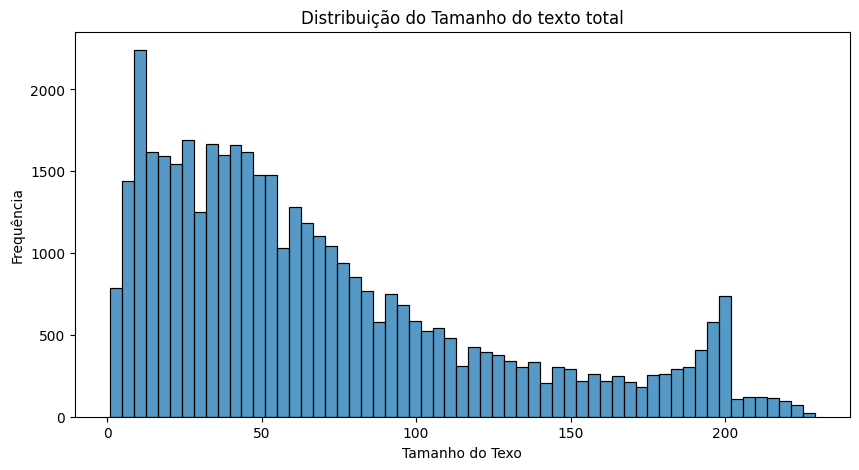

In [12]:
plt.figure(figsize=(10,5))
sns.histplot(data=df_filtered, x='len_full_text')
plt.title('Distribuição do Tamanho do texto total')
plt.xlabel('Tamanho do Texo')
plt.ylabel('Frequência')
plt.show()

#### 2.2.2) Distribuição por Nota

Ao avaliar a volumetria por nota, percebe-se que há uma distribuição bem desigual, especialemnte entre as notas 1 e 5, portanto o ideal seria mapear as notas para suas classificações ('Positiva' - 4,5; Neutra - 3; 'Negativa' - 1,2)

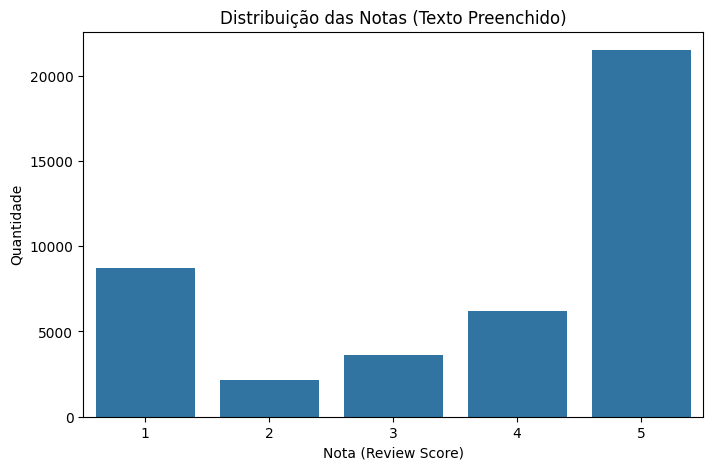

In [13]:
plt.figure(figsize=(8,5))
sns.countplot(data=df_filtered, x='review_score')
plt.title('Distribuição das Notas (Texto Preenchido)')
plt.xlabel('Nota (Review Score)')
plt.ylabel('Quantidade')
plt.show()

In [14]:
df_filtered['review_score_adapted'] = df_filtered['review_score'].apply(lambda s: 'Negativo' if s in (4,5) else 'Positivo' if s in (1,2) else 'Neutro')

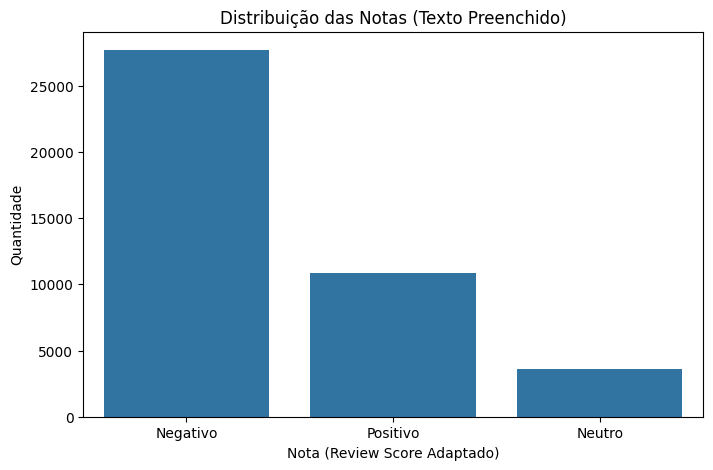

In [15]:
# Distribuição das notas classificadas

plt.figure(figsize=(8,5))
sns.countplot(data=df_filtered, x='review_score_adapted')
plt.title('Distribuição das Notas (Texto Preenchido)')
plt.xlabel('Nota (Review Score Adaptado)')
plt.ylabel('Quantidade')
plt.show()

#### 2.2.3) Avaliação da Volumetria do Texto

In [16]:
# Avaliação de frequência de expressões repetidas

df_volumetry = df_filtered['formated_text'].value_counts().reset_index(name='frequency') 

df_volumetry.head(15)

,formated_text,frequency
0,muito bom,568
1,recomendo,424
2,bom,412
3,ótimo,306
4,excelente,268
5,otimo,260
6,super recomendo,155
7,ok,130
8,boa,118
9,tudo ok,111


In [17]:
df_volumetry

,formated_text,frequency
0,muito bom,568
1,recomendo,424
2,bom,412
3,ótimo,306
4,excelente,268
5,otimo,260
6,super recomendo,155
7,ok,130
8,boa,118
9,tudo ok,111
